## <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/prof/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>

<center>Curs 6 - Regresie Uni- și Multivariată</center>

**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prof/SEED/blob/main/cursuri/04-regresie/curs-04a-regresie-uni-multivariata.ipynb)

In [ ]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/prof/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/04-regresie
sys.path.insert(0, os.path.abspath("../.."))

Importuri necesare de module Python.

In [45]:
#from pathlib import Path

import pandas as pd
import numpy as np

from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence

from pygam import LinearGAM, s, l
from pygam.datasets import wage


import seaborn as sns
import matplotlib.pyplot as plt

from dmba import stepwise_selection
from dmba import AIC_score

In [46]:
#! pip install dmba pygam

Activăm grafica `inline`

In [47]:
%matplotlib inline

Definiți căile către seturile de date. Dacă nu vă păstrați datele în același director cu codul, adaptați numele căilor.

In [48]:
DATA = './date'
LUNG_CSV = DATA + '/LungDisease.csv'
HOUSE_CSV = DATA +'/house_sales.csv'

Poate cel mai frecvent obiectiv în statistică este de a răspunde la întrebarea: este variabila $X$ (sau, mai probabil în majoritatea cazurilor - sunt variabilele $X_1, ... ,X_p$) asociată(e) cu variabila $Y$? Care este relația dintre ele și putem să folosim $X$ pentru a prezice $Y$?

Nicăieri legătura dintre statistică și știința datelor nu este mai puternică decât în domeniul predicției - în special predicția unei variabile (țintă) bazată pe valorile altor variabile „predictoare”. O altă conexiune importantă este în zona detectării anomaliilor, unde diagnosticul de regresie destinat inițial analizei datelor și îmbunătățirii modelului de regresie poate fi utilizat pentru a detecta înregistrări neobișnuite. Variante incipiente ale corelației și regresiei liniare datează de peste un secol.

# Regresia liniară simplă

Regresia liniară simplă/univariată modelează relația dintre mărimea  a două variabile - de exemplu, pe măsură ce X crește, și Y crește. Sau pe măsură ce X crește, Y scade. Corelația este o altă modalitate de a măsura modul în care două variabile sunt legate: vezi secțiunea „Corelație”. Diferența este că, în timp ce corelația măsoară puterea unei asocieri între două variabile, regresia cuantifică natura relației.

## Terminologie

#### Răspuns/variabilă țintă

Variabila pe care încercăm să o prezicem.

>Sinonime
> - variabilă dependentă, variabilă Y, țintă, rezultat


#### Variabila independenta

Variabila folosită pentru a prezice răspunsul.

> Sinonime
> - X-variabilă, caracteristică, atribut, covariată

#### Observație

Vectorul valorilor de predictor și rezultat pentru un anumit individ sau caz.

> Sinonime
> - înregistrare, caz, exemplu

#### Intercept

Interceptul dreptei de regresie - adică valoarea prezisă când $X = 0$.

> Sinonime
> - $𝑏_0, \beta_0$

Coeficientul de regresie

#### Panta dreptei de regresie.

> Sinonime
> - panta, $𝑏_1, 𝛽_1$, estimări ale parametrilor, ponderi

#### Valori potrivite (fitted values)
Estimările $Y^i$ obţinute din dreapta de regresie.

#### Metoda celor mai mici pătrate 

Metoda de determinare a coeficieților a unei regresii prin minimizarea sumei reziduurilor pătrate.

## Ecuația regresiei liniare

Regresia liniară simplă estimează exact cât de mult se va schimba Y atunci când X se schimbă cu o anumită cantitate. Cu coeficientul de corelație, variabilele $X$ și $Y$ sunt interschimbabile. Cu regresie, încercăm să prezicăm variabila $Y$ din $X$ folosind o relație liniară (adică o linie):

$$𝑌 = 𝑏_0 + 𝑏_1X$$

Citim acest lucru ca „$Y$ este egal cu $b_1$ ori $X$, plus o constantă $b_0$”. Simbolul $𝑏_0$ este cunoscut ca intercept (sau constantă), iar simbolul $𝑏_1$ ca panta dreptei. Ambele apar în ca și coeficienți, deși, în general, termenul coeficient este adesea rezervat pentru $𝑏_1$. Variabila $Y$ este cunoscută ca răspuns sau variabilă dependentă, deoarece depinde de $X$. Variabila $X$ este cunoscută ca predictor sau variabilă independentă. Comunitatea de învățare automată tinde să folosească alți termeni, numind $Y$ țintă (<i>target</i>) și $X$ un vector caracteristic (<i>feature vector</i>).

Luați în considerare graficul de dispersie din figura următoare care afișează numărul de ani în care un lucrător a fost expus la praf de bumbac (Expunere) față de o măsură a capacității pulmonare (PEFR - peak expiratory flow rate sau  „debit expirator de vârf”). Cum este PEFR legat de expunere? Este greu de spus doar pe baza imaginii.

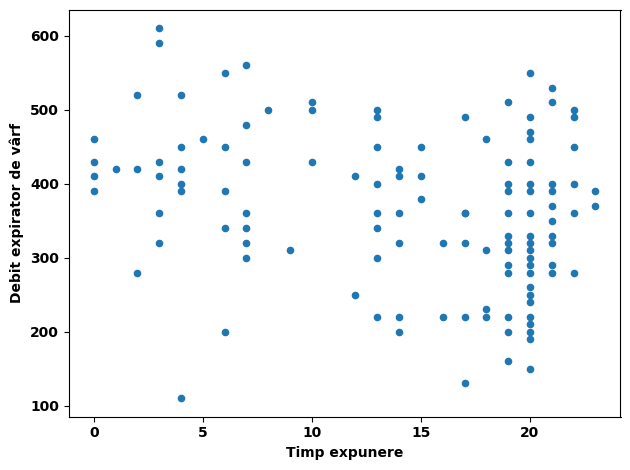

In [49]:
lung = pd.read_csv(LUNG_CSV)

lung.plot.scatter(x='Exposure', y='PEFR')

plt.tight_layout()
plt.xlabel("Timp expunere")
plt.ylabel("Debit expirator de vârf")
plt.show()

Regresia liniară simplă încearcă să găsească „cea mai bună” linie pentru a prezice PEFR de răspuns
în funcţie de variabila predictor Expunere.

$$\begin{equation}\large PEFR = 𝑏_0 + 𝑏_1Expunere\end{equation}$$

Pentru asta vom folosi modelul `LinearRegression` din modulul _scikit-learn_.

In [50]:
predictori= ['Exposure']
rezultat = 'PEFR'

model = LinearRegression()
model.fit(lung[predictori], lung[rezultat])

print(f'Intercept: {model.intercept_:.3f}')
print(f'Coeficient variabilă Exposure/Expunere: {model.coef_[0]:.3f}')

Intercept: 424.583
Coeficient variabilă Exposure/Expunere: -4.185


Intercept-ul, sau $𝑏_0$, este 424,583 și poate fi interpretată ca PEFR estimat pentru un lucrător cu expunere zero ani. Coeficientul de regresie, sau 𝑏1, poate fi interpretat după cum urmează: pentru fiecare an suplimentar în care un lucrător este expus la praf de bumbac, măsurarea PEFR a lucrătorului este redusă cu –4,185.

Reprezentăm grafic funcția obținută folosind modulul `matplotlib`. 

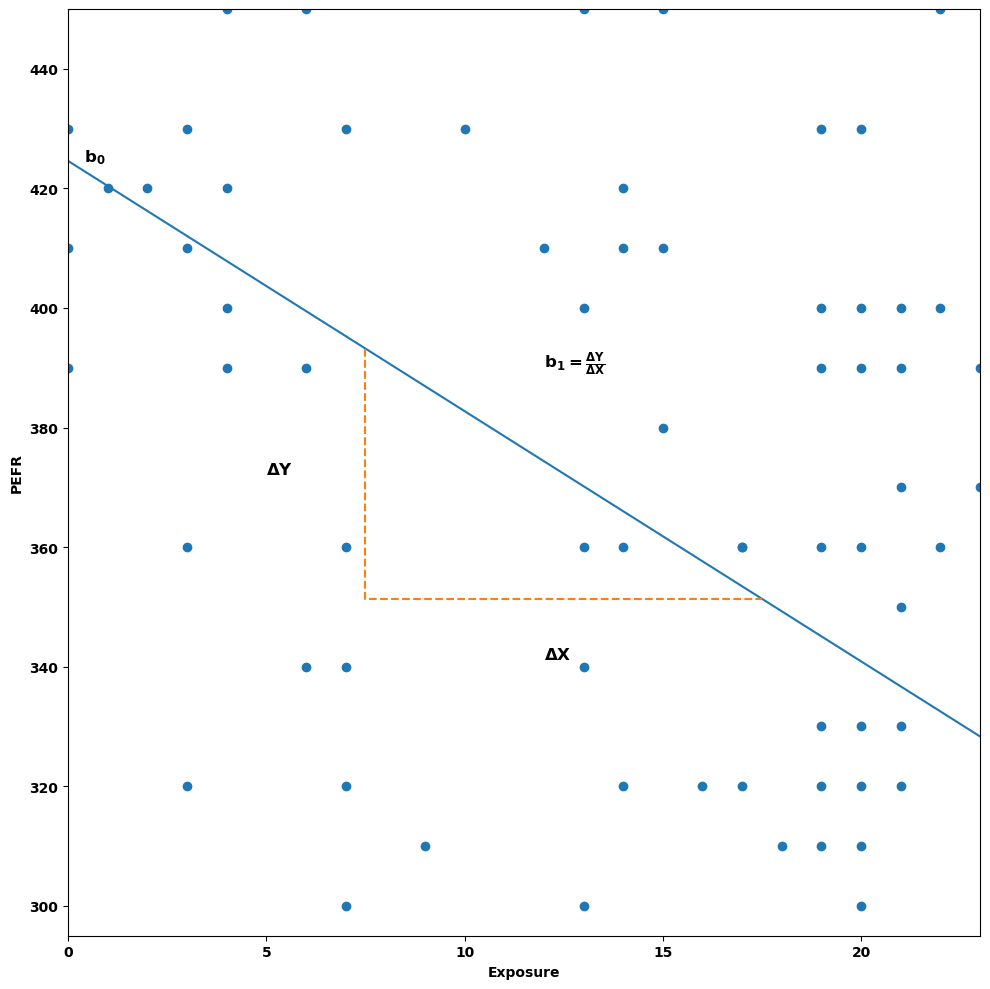

In [51]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_xlim(0, 23)
ax.set_ylim(295, 450)

ax.set_xlabel('Exposure')
ax.set_ylabel('PEFR')
ax.plot((0, 23), model.predict(pd.DataFrame({'Exposure': [0, 23]})))
ax.text(0.4, model.intercept_, r'$b_0$', size='larger')

x = pd.DataFrame({'Exposure': [7.5,17.5]})
y = model.predict(x)
ax.plot((7.5, 7.5, 17.5), (y[0], y[1], y[1]), '--')
ax.text(5, np.mean(y), r'$\Delta Y$', size='larger')
ax.text(12, y[1] - 10, r'$\Delta X$', size='larger')
ax.text(12, 390, r'$b_1 = \frac{\Delta Y}{\Delta X}$', size='larger')

ax.scatter(x=lung['Exposure'], y=lung['PEFR'])
plt.tight_layout()
plt.show()

## Antrenarea modelului și valori reziduale

În practică observăm valori și se admite o eroare (legată de incertitudinea acestor observații) care se presupune a fi distribuită normal cu o medie 0 și variație standard $\sigma_e$. Astfel: 
$$𝑌_𝑖 = 𝑏_0 + 𝑏_1*𝑋_𝑖 + 𝑒_𝑖, 1\le i\le N$$

unde $N$ e numărul observațiilor.

Valorile ajustate, denumite și valorile prezise, ​​sunt de obicei notate cu
$\hat{𝑌}_𝑖$ (hat-Y). Acestea sunt date de:

$$\hat{𝑌}_𝑖 = \hat{𝑏}_0 + \hat{b}_1*𝑋_𝑖, 1\le i\le N$$

Notația $ \hat{𝑏}_0$ și $ \hat{𝑏}_1$ indică faptul că coeficienții sunt estimați și nu cunoscuți.

Metoda `predict` a unui model _scikit-learn_ antrenat cu metoda `fit` poate fi folosită pentru prognoza pe datele din antrenament sau pe date noi.

## Notație Hat: Estimări versus valori cunoscute
Notația „pălărie” (^) este folosită pentru a diferenția între estimări și valorile cunoscute. Deci simbolul $\hat{b}$ („b-pălărie”) este o estimare a parametrului necunoscut $b$. De ce fac statisticienii diferența între valoarea estimată și valoarea adevărată? Estimarea are incertitudine, în timp ce valoarea adevărată este fixă.

Calculăm reziduurile $\hat{𝑒}_𝑖$ scăzând valorile prezise din datele originale:

$\begin{equation}\large\hat{𝑒}_𝑖 = 𝑌_𝑖 - \hat{𝑌}_𝑖, \normalsize 1\le i\le N.\end{equation}$
Graficul următor ilustrează reziduurile de la linia de regresie antrenată pe datele pulmonare. Reziduurile sunt lungimea liniilor întrerupte verticale de la date la linie.

In [52]:
fitted = model.predict(lung[predictori])
residuals = lung[rezultat] - fitted

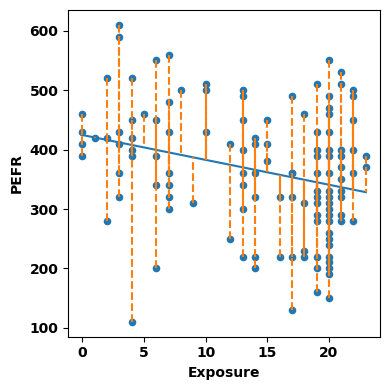

In [53]:
ax = lung.plot.scatter(x='Exposure', y='PEFR', figsize=(4, 4))
ax.plot(lung.Exposure, fitted)
for x, yactual, yfitted in zip(lung.Exposure, lung.PEFR, fitted): 
    ax.plot((x, x), (yactual, yfitted), '--', color='C1')

plt.tight_layout()
plt.show()

## Antrenarea modelului

Cum se antrenează modelul pe date? Când există o relație clară, am putea
potrivi linia cu mâna. În practică, linia de regresie este estimarea
care minimizează suma pătratelor reziduale sau RSS:
$$RSS = \sum_i (Y_i - \hat{Y}_i)^2 = \sum_i (Y_i - \hat{b}_0 - \hat{b}_1* X_i)^2$$

Estimările $\hat{b}_0$ și $\hat{b}_1$ sunt valorile care minimizează RSS.

Metoda de minimizare a sumei reziduurilor pătrate este denumită regresie a celor mai mici pătrate. Este adesea atribuită lui _Carl Friedrich Gauss_, matematicianul german, dar a fost publicată pentru prima dată de matematicianul francez _Adrien-Marie Legendre_ în 1805. Regresia cu cele mai mici pătrate duce la o formulă simplă pentru a calcula coeficienții:
$\begin{equation}\large\hat{b}_1 =\frac{ \sum_i (𝑌_𝑖 - \bar{𝑌}) (𝑋_𝑖 - \bar{𝑋})}{\sum_i(X_i-\bar{X})^2}\end{equation}$
$\begin{equation}\large\hat{b}_0 = \bar{Y} - \hat{b}_1 * \bar{X}\end{equation}$

unde $\bar{Y},\bar{X}$ sunt mediile variabilelor.
Din punct de vedere istoric, comoditatea de calcul este un motiv pentru utilizarea pe scară largă a celor mai mici pătrate în regresie. Odată cu apariția datelor mari, viteza de calcul este încă un factor important. 

Regresia bazată pe cele mai mici pătrate, precum și media, sunt sensibile la valori aberante, deși aceasta tinde să fie o problemă semnificativă doar în problemele de dimensiuni mici sau moderate. 

## Studiu de caz: date despre mașini

In [54]:
import pandas as pd

#incarcam setul de date cu preturi de masini
df_sample = pd.read_csv("./date/CarPrice_Assignment.csv")
df_sample.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


### Scurt intermezzo de preprocesare a datelor

In [55]:
df_sample.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [56]:
#separam brandul de model
CompanyName = df_sample['CarName'].apply(lambda x : x.split(' ')[0])
df_sample.insert(3,"CompanyName",CompanyName)
df_sample.drop(['CarName'],axis=1,inplace=True)
df_sample.head()
df_sample.CompanyName.unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'maxda', 'mazda', 'buick', 'mercury',
       'mitsubishi', 'Nissan', 'nissan', 'peugeot', 'plymouth', 'porsche',
       'porcshce', 'renault', 'saab', 'subaru', 'toyota', 'toyouta',
       'vokswagen', 'volkswagen', 'vw', 'volvo'], dtype=object)

Rezolvăm micile greșeli:

In [57]:
df_sample.CompanyName = df_sample.CompanyName.str.lower()

def replace_name(a,b):
    df_sample.CompanyName.replace(a,b,inplace=True)
replace_name('alfa-romero','alfa-romeo')
replace_name('maxda','mazda')
replace_name('porcshce','porsche')
replace_name('toyouta','toyota')
replace_name('vokswagen','volkswagen')
replace_name('vw','volkswagen')

df_sample.CompanyName.unique()

array(['alfa-romeo', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'mazda', 'buick', 'mercury', 'mitsubishi',
       'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab',
       'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

Să vedem coloanele:

In [58]:
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CompanyName       205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [59]:
#construim un atribut derivat: consum mediu
df_sample['fueleconomy'] = (0.55 * df_sample['citympg']) + (0.45 * df_sample['highwaympg'])

In [60]:
df_sample.describe().T

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


In [61]:
#grupam companiile dupa pretul mediu al modelelor
df_sample['price'] = df_sample['price'].astype('int')
temp = df_sample.copy()
table = temp.groupby(['CompanyName'])['price'].mean()
temp = temp.merge(table.reset_index(), how='left',on='CompanyName')

bins = [0,10000,20000,40000]

cars_bin=['Budget','Medium','Highend']

df_sample['carsrange'] = pd.cut(temp['price_y'],bins,right=False,labels=cars_bin)

df_sample.head()

,car_ID,symboling,CompanyName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,fueleconomy,carsrange
0,1,3,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,...,3.47,2.68,9.0,111,5000,21,27,13495,23.70,Medium
1,2,3,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,...,3.47,2.68,9.0,111,5000,21,27,16500,23.70,Medium
2,3,1,alfa-romeo,gas,std,two,hatchback,rwd,front,94.5,...,2.68,3.47,9.0,154,5000,19,26,16500,22.15,Medium
3,4,2,audi,gas,std,four,sedan,fwd,front,99.8,...,3.19,3.40,10.0,102,5500,24,30,13950,26.70,Medium
4,5,2,audi,gas,std,four,sedan,4wd,front,99.4,...,3.19,3.40,8.0,115,5500,18,22,17450,19.80,Medium


In [62]:
df_sample.groupby('carsrange',as_index = False,observed=True)['price'].agg(['min','max'])


,carsrange,min,max
0,Budget,5118,17669
1,Medium,5195,23875
2,Highend,16430,45400


### Spargerea datelor în date de antrenament și date de test

Impărțim setul de date în train/test.

Vom folosi o alegere aleatorie, dar fixată odată aleasă prin specificarea parametrului `random_state`.

Specificarea acestui parametru face posibilă verificarea și reproducerea ulterioară și este utilă la DEBUG. 

`ATENȚIE` Dacă dorim ca la fiecare rulare să obținem cu adevărat spargeri diferite, parametrul random_state trebuie omis.

## PENTRU TEME: alegeți ca și <i>random_state</i> numărul de ordine din catalog

In [63]:
# split in date de antrenament si test
from sklearn.model_selection import train_test_split

#activam random_state pentru o alegere aleatorie dar persistenta (pentru a putea reproduce ulterior. In practica,
# atunci cand vom teste de mai mult ori, vom renunta la random_state)


##______________________________________________

## PENTRU TEME: alegeti ca si random_state numarul de ordine din catalog

##________________________________________________

traindf, testdf = train_test_split(df_sample, test_size=0.2, random_state=42)

# testing set ~ 20% din total data; training ~ 80%
print("Shape of full dataset is: {0}".format(df_sample.shape))
print("Shape of training dataset is: {0}".format(traindf.shape))
print("Shape of test dataset is: {0}".format(testdf.shape))
testdf.highwaympg.sum()

Shape of full dataset is: (205, 28)
Shape of training dataset is: (164, 28)
Shape of test dataset is: (41, 28)


1290

In [64]:
df_sample.dtypes

car_ID                 int64
symboling              int64
CompanyName           object
fueltype              object
aspiration            object
doornumber            object
carbody               object
drivewheel            object
enginelocation        object
wheelbase            float64
carlength            float64
carwidth             float64
carheight            float64
curbweight             int64
enginetype            object
cylindernumber        object
enginesize             int64
fuelsystem            object
boreratio            float64
stroke               float64
compressionratio     float64
horsepower             int64
peakrpm                int64
citympg                int64
highwaympg             int64
price                  int32
fueleconomy          float64
carsrange           category
dtype: object

## Antrenare model simplu de regresie



Pentru a încerca o regresie liniară simplă, să încercăm prezicerea prețului pornind de la date știute. 
Să încercăm cu horsepower = cai putere:

In [65]:
import numpy as np
y_train = np.array(traindf.price)
X_train = np.array(traindf.horsepower )
display(X_train)
# adaugăm coloana termenului liber (artificiu specific regresiei, nu o să-l mai vedem la alte modele)
X_train = X_train.reshape(X_train.shape[0], 1)
X_train 

array([ 72,  95,  62,  69,  86,  68,  73,  95, 145,  70, 161,  55,  92,
        69, 110, 116, 101, 207,  68,  82, 160,  92, 175,  73,  76, 121,
        76, 143, 100,  70, 160,  73,  68,  95, 112, 101, 145,  68, 102,
        68, 160, 114, 142, 154,  68,  90,  68, 207,  88,  69,  76,  95,
        84,  68, 110,  68,  76, 101, 162,  70, 110, 102, 207, 114,  82,
       115,  60,  97,  68,  97,  82, 101,  84,  68,  62, 116, 111,  52,
        85, 123, 106,  84,  70, 112,  88,  86,  95,  88, 102,  62,  90,
        88,  86, 116, 176,  69,  56,  78,  82, 102, 200,  68, 110,  85,
        70,  90, 262, 116,  76, 110,  95,  69, 145, 156,  85,  69, 140,
       121,  84,  92,  90, 182, 155, 156, 110, 116, 162,  64,  68,  97,
        68, 160, 116, 135, 176, 116,  68, 101,  70, 114, 288,  86,  70,
        88, 111,  68, 111,  90,  62, 152,  97,  95, 116, 184,  68, 114,
        70, 100, 155, 160, 121,  69, 161, 152], dtype=int64)

array([[ 72],
       [ 95],
       [ 62],
       [ 69],
       [ 86],
       [ 68],
       [ 73],
       [ 95],
       [145],
       [ 70],
       [161],
       [ 55],
       [ 92],
       [ 69],
       [110],
       [116],
       [101],
       [207],
       [ 68],
       [ 82],
       [160],
       [ 92],
       [175],
       [ 73],
       [ 76],
       [121],
       [ 76],
       [143],
       [100],
       [ 70],
       [160],
       [ 73],
       [ 68],
       [ 95],
       [112],
       [101],
       [145],
       [ 68],
       [102],
       [ 68],
       [160],
       [114],
       [142],
       [154],
       [ 68],
       [ 90],
       [ 68],
       [207],
       [ 88],
       [ 69],
       [ 76],
       [ 95],
       [ 84],
       [ 68],
       [110],
       [ 68],
       [ 76],
       [101],
       [162],
       [ 70],
       [110],
       [102],
       [207],
       [114],
       [ 82],
       [115],
       [ 60],
       [ 97],
       [ 68],
       [ 97],
       [ 82],
      

In [66]:
y_test = np.array(testdf.price)
X_test = np.array(testdf.horsepower)
X_test = X_test.reshape(X_test.shape[0], 1)

In [67]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [68]:
#cream model linear
regression = LinearRegression()

#fit model
regression.fit(X_train, y_train)

#prognoza cu model - cat de bine se potriveste modelul pe datele de antrenament
predicted_y = regression.predict(X_train)

#variatia explicata
r2 = regression.score(X_train, y_train)
print(f'R^2 train = {r2:.5}')


#prognoza cu model
predicted_y = regression.predict(X_test)

#variatia explicata
r2 = regression.score(X_test, y_test)
print(f'R^2 test = {r2:.5}')

R^2 train = 0.6577
R^2 test = 0.63261


Este util și să vedem cât de bun a fost antrenamentul/potrivirea/pasul 'fit'

In [69]:
print("Variație explicată la antrenament: ", regression.score(X_train, y_train))

print("MSE pe date de test:",mean_squared_error(predicted_y, y_test))
print("MSE pe date de antrenament:",mean_squared_error(y_train, regression.predict(X_train)))

print('Coeficienți: \n beta0 =', regression.intercept_,',beta1 =', regression.coef_[0])

Variație explicată la antrenament:  0.657697534125993
MSE pe date de test: 29003054.40181304
MSE pe date de antrenament: 20414149.84769232
Coeficienți: 
 beta0 = -3126.846516877473 ,beta1 = 156.1610755790522


`Info` E normal ca la antrenament să obținem eroare mai mică și $R^2$ mai mare - acolo am optimizat modelul. E important de asemenaea să obținem rezultate asemănătoare pe date noi, pe date de test.

În cele ce urmează facem două grafice:

- în primul vom compara pentru datele nefolosite în antrenament (dar pentru care știm prețul) prognoza cu prețul real:
    - pe axa Ox prețul real, pe Oy prețul prognozat; de-alungul diagonalei prognoza nimerește realitatea
    
    `Info` O prognoză bună ar fi reprezentată aici de un nor foarte apropiat de diagonală.
    
 
- în cel de-al doilea vom prezenta atât datele folosite în antrenament cât și datele 'noi', nefolosite în antrenament. Putem vedea dacă datele noi au fost diferite de datele vechi, daca au ceva cazuri extreme, etc.
    - în acest caz pe Ox am pus variabila folosită în regresie - caii putere, pe Oy observația dorită - prețul

In [70]:
grid = np.linspace(np.min(df_sample.price), np.max(df_sample.price), 100)
xgrid = np.linspace(np.min(df_sample.horsepower), np.max(df_sample.horsepower), 100)

###################################################################################33
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(rows=2, cols=1)

fig.add_trace(
    go.Scatter(x= y_test, 
               y = predicted_y,mode='markers',
               name = 'Preț real vs Prognoză'),
    row=1, col=1
)
fig.add_trace(
    go.Scatter(x = grid, y = grid, mode='lines',
               name = 'Diagonala x=y'),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(x=traindf.horsepower, 
               y=traindf.price,mode='markers',
               name = 'Date antrenament'),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(x=testdf.horsepower, 
               y=testdf.price,mode='markers',
               name = 'Date test'),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(x=xgrid, 
               y=regression.predict(xgrid.reshape(100, 1)),mode='lines',
               name = 'Linia de regresie'),
    row=2, col=1
)

fig.update_layout(height=1200, width=800, title_text="Vizualizare rezultate predicție pe datele de test")

# Update xaxis properties
fig.update_xaxes(title_text="Prețuri mașini", row=1, col=1)
fig.update_xaxes(title_text="Cai putere", row=2, col=1)

# Update yaxis properties
fig.update_yaxes(title_text="Prețuri prognozate", row=1, col=1)
fig.update_yaxes(title_text="Prețuri mașini",  row=2, col=1)


fig.show()

# <i> Compararea modelelor de regresie. Aplicație: top predictori</i>

#### Putere de predicție individuala: Predictive Residual Sum of Squares

Vom folos în funcția de mai jos de mai multe ori regresia liniară simplă pentru a evalua puterea de predicție a fiecărui atribut în parte în prezicerea prețului - practic, vom prezice pe rând una din observații pe baza modelelor făcute cu toate celelalte înregistrări. 



In [71]:
cars_lr = traindf[['price', 'fueltype', 'aspiration','carbody', 'drivewheel','wheelbase',
                  'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'boreratio','horsepower', 
                    'fueleconomy', 'carlength','carwidth', 'carsrange']]

In [72]:
cars_lr.dtypes

price                int32
fueltype            object
aspiration          object
carbody             object
drivewheel          object
wheelbase          float64
curbweight           int64
enginetype          object
cylindernumber      object
enginesize           int64
boreratio          float64
horsepower           int64
fueleconomy        float64
carlength          float64
carwidth           float64
carsrange         category
dtype: object

Pentru a putea lucra cu atributele categoriale trebuie să le convertim cumva în numere.
Există diverse moduri de a rezolva aceasta problema - vom folosi aici funcția din pandas care realizează transformarea `One-Hot-Encoding`:

### One-Hot-Encoding via get_dummies() din pandas


##### Recapitulare one-hot-encoding

Exemplific mai jos generarea de variabile dummy-când e vorba de variabile categoriale cu două niveluri putem renunța la una dintre coloanele generate. De altfel, acelasi lucru e valabile si pentru celelalte situații- dacă sunt mai multe niveluri, și din coloanele dummy renunțăm la una, rămâne vectorul cu 0-uri să reprezinte acea valoare.

In [73]:

df1 = pd.DataFrame({'A': ['a', 'b', 'a'], 'B': ['b', 'a', 'c'],
                   'C': [1, 2, 3]})
display(df1)

display(pd.get_dummies(df1))#, prefix=['A', 'B'])


pd.get_dummies(df1, drop_first = True)

,A,B,C
0,a,b,1
1,b,a,2
2,a,c,3


,C,A_a,A_b,B_a,B_b,B_c
0,1,True,False,False,True,False
1,2,False,True,True,False,False
2,3,True,False,False,False,True


,C,A_b,B_b,B_c
0,1,False,True,False
1,2,True,False,False
2,3,False,False,True


Pentru că avem multe coloane, voi face o funcție care să transforme dataframe-ul într-unul nou cu coloanele aferente, făcând transfomarea pentru o coloană în parte.

In [74]:

def dummies(x,df):
    
    temp = pd.get_dummies(df[x], drop_first = True, prefix = x)
    df = pd.concat([df, temp], axis = 1)
    df.drop([x], axis = 1, inplace = True)
    
    return df


In [75]:
cars_lr = dummies('aspiration',cars_lr)
cars_lr = dummies('carbody',cars_lr)
cars_lr = dummies('drivewheel',cars_lr)
cars_lr = dummies('enginetype',cars_lr)
cars_lr = dummies('cylindernumber',cars_lr)
cars_lr = dummies('carsrange',cars_lr)
cars_lr = dummies('fueltype',cars_lr)

In [32]:
cars_lr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 164 entries, 66 to 102
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  164 non-null    int32  
 1   wheelbase              164 non-null    float64
 2   curbweight             164 non-null    int64  
 3   enginesize             164 non-null    int64  
 4   boreratio              164 non-null    float64
 5   horsepower             164 non-null    int64  
 6   fueleconomy            164 non-null    float64
 7   carlength              164 non-null    float64
 8   carwidth               164 non-null    float64
 9   aspiration_turbo       164 non-null    bool   
 10  carbody_hardtop        164 non-null    bool   
 11  carbody_hatchback      164 non-null    bool   
 12  carbody_sedan          164 non-null    bool   
 13  carbody_wagon          164 non-null    bool   
 14  drivewheel_fwd         164 non-null    bool   
 15  drivewheel

## Validarea încrucișată (Cross-validation) 

Când spargem datele, vrem să fim siguri că modelarea nu depinde de o anume spargere.

Putem face mii de teste, spărgând aleatoriu datele și măsurând cumva cât din date am explorat.

Alternativ, putem face o validare încrucișată - spargem setul de date într-un număr fix de bucăți de aceeiași dimensiue, spargerea fiind aleatorie. Ținem pe rând o bucată pentru test și antrenăm pe restul - astfel vom crea un număr de modele egal cu numărul de bucăți în care spargem datele. Dacă variația din rezultate nu este mare, înseamnă că avem un model bun. 

In [78]:
import numpy as np
from sklearn.model_selection import KFold

   
def cross_validation_score(df, model,k, target, covs = None):
    
    # compute press score:
    res = []
    
    # split in 10 equal parts for crossvalidation
    kf = KFold(n_splits=k)
    
    
    for train_index, test_index in kf.split(df):
           
        
        X_train = None
        X_test = None
        
        if covs is not None:
            
            X_train = df[covs].iloc[train_index]
            X_test = df[covs].iloc[test_index]
        
        y_train = df[[target]].iloc[train_index]
        y_test = df[[target]].iloc[test_index]
        
        #print('training')
        # train on X_temp
        trained_model = train_model(model, X_train, y_train)
        
        #print(model, trained_model)
        if model == 'base_model':
            trained_model = [trained_model[0]] *len(y_test)
        
        #print(model, trained_model)
#         print('compute error')
#         print()
        # forecast and compute MSE        
        y_hat = forecast(model, trained_model,X_test)
        
        #print(y_test.shape[0],  len(y_hat))
        res.append( np.sum((y_test.values -y_hat )**2)/len(y_test))
        
    return np.mean(res), np.std(res)

La antrenament vom produce nu doar modelele simple de regresie, dar și un model de bază cu care să comparăm.

În cazul nostru, al prețurilor pentru mașini, putem de exemplu porni cu media ca fiind un estimator simplu al prețurilor. Să vedem care din potențialii predictori bate media!

In [79]:
# regersia liniară și modelul de bază 
def train_model(model, X,y):
    
    if model == 'base_model':
        
        # predicție cu modelul de bază - media
        return sum(y.values)/len(y)
    
    else: # regeresie liniară
        
        reg = LinearRegression()
        
        #print(X.values[0:10], y.values[0:10])
        reg.fit(X.values, y.values)
    
        return reg

def forecast(model,trained_model, X):
    
    if model == 'base_model':
        
        return trained_model # returnează media
    
    else: # regresie (multi)liniară 
        
        return trained_model.predict(X.values)

In [80]:
cars_lr.columns

Index(['price', 'wheelbase', 'curbweight', 'enginesize', 'boreratio',
       'horsepower', 'fueleconomy', 'carlength', 'carwidth',
       'aspiration_turbo', 'carbody_hardtop', 'carbody_hatchback',
       'carbody_sedan', 'carbody_wagon', 'drivewheel_fwd', 'drivewheel_rwd',
       'enginetype_dohcv', 'enginetype_l', 'enginetype_ohc', 'enginetype_ohcf',
       'enginetype_ohcv', 'enginetype_rotor', 'cylindernumber_five',
       'cylindernumber_four', 'cylindernumber_six', 'cylindernumber_twelve',
       'cylindernumber_two', 'carsrange_Medium', 'carsrange_Highend',
       'fueltype_gas'],
      dtype='object')

Să evaluăm diferența procentuală în eroarea de modelare obținută de un model vs modelul de bază:

In [81]:
# predictorii 
pred_vars = [  'wheelbase', 'curbweight', 'enginesize', 'boreratio',
       'horsepower', 'fueleconomy', 'carlength', 'carwidth',
       'aspiration_turbo', 'carbody_hardtop', 'carbody_hatchback',
       'carbody_sedan', 'carbody_wagon', 'drivewheel_fwd', 'drivewheel_rwd',
       'enginetype_dohcv', 'enginetype_l', 'enginetype_ohc', 'enginetype_ohcf',
       'enginetype_ohcv', 'enginetype_rotor', 'cylindernumber_five',
       'cylindernumber_four', 'cylindernumber_six', 'cylindernumber_twelve',
       'cylindernumber_two', 'carsrange_Medium', 'carsrange_Highend',
       'fueltype_gas']

X = cars_lr[pred_vars]

## tinta
y = cars_lr[['price']] 

# puterea de predictie individuala

dict_list = []
base_model = np.round(float(((y - y.mean())**2).sum().iloc[0] / len(y)), 2)#cross_validation_score(cars_lr,'base_model', 10, target = 'price')
print('base model: ',base_model)
for _,col in enumerate(pred_vars):
    individual_press ={}

    individual_press['feature_name'] = col
    individual_press['PRESS_MeanCV_MSE'],_ = cross_validation_score(cars_lr[[col, 'price'] ], 
                                                       'lin-reg', 10, 
                                                       target = 'price',
                                                      covs = [col])#[0][0]
    individual_press['PRESS_MeanCV_MSE'] = np.round(individual_press['PRESS_MeanCV_MSE'],2)
    individual_press['base model_OverAllPriceMean'] = base_model
    individual_press['PRESS_pct_diff'] =max(0,np.round(100*(1-individual_press['PRESS_MeanCV_MSE']/base_model),1))#[0]),1)
    dict_list.append(individual_press)

individual_press_final = pd.DataFrame(dict_list)


top_features = individual_press_final.sort_values(by = ["PRESS_pct_diff"], ascending = [False])
top_features = top_features.rename(columns = {'PRESS_pct_diff':'Prediction Power'})
top_features

base model:  59637752.81


,feature_name,PRESS_MeanCV_MSE,base model_OverAllPriceMean,Prediction Power
2,enginesize,15715878.29,59637752.81,73.6
1,curbweight,19589607.15,59637752.81,67.2
4,horsepower,21364940.91,59637752.81,64.2
27,carsrange_Highend,24748489.74,59637752.81,58.5
7,carwidth,27251611.06,59637752.81,54.3
5,fueleconomy,30375157.81,59637752.81,49.1
22,cylindernumber_four,30998108.02,59637752.81,48.0
6,carlength,35893570.84,59637752.81,39.8
14,drivewheel_rwd,36896106.69,59637752.81,38.1
13,drivewheel_fwd,39548873.46,59637752.81,33.7


### Terminologie de regresie
Când analiștii și cercetătorii folosesc termenul de regresie în sine, de obicei se
referă la regresia liniară; accentul se pune de obicei pe dezvoltarea unui model liniar pentru
a explica relația dintre variabilele independente și o variabilă rezultat numeric.
În sensul său statistic formal, regresia include și modele neliniare care
produc o relație funcțională între predictori și variabile rezultat. În
comunitatea de învățare automată, termenul este de asemenea folosit ocazional pentru a se referi
la utilizarea oricărui model predictiv care produce un rezultat numeric prezis
(ca să se deosebească de metodele de clasificare care prezic un rezultat binar sau categoric).

## Predicție versus inferență

Din punct de vedere istoric, o utilizare principală a regresiei a fost de a descoperi o presupusă relație liniară
între variabilele predictoare și o variabilă de rezultat. Scopul a fost
de a înțelege o relație și a o explica folosind datele. În acest caz, accentul principal este pe coeficienții $\hat{b}$ (în cazul 1-dim panta dreptei). Economiștii doresc să cunoască relația dintre cheltuielile consumatorilor
și creșterea PIB-ului. Oficialii de sănătate publică ar putea dori să înțeleagă dacă o
campania de informare publică este eficientă în promovarea practicilor de prevenire a cancerului de prostată. În aceste
cazuri, accentul nu este pe prezicerea cazurilor individuale, ci mai degrabă pe înțelegerea
 de ansamblu a relației.
 
Odată cu apariția datelor mari, regresia este utilizată pe scară largă pentru a forma un model de predicție pentru
rezultate individuale pe date noi, mai degrabă decât explicarea datelor - model predictiv și nu un model de inferență. În acest caz, principalele elemente de interes sunt valorile ajustate $\hat{𝑌}$. În
marketing, regresia poate fi folosită pentru a prezice schimbarea veniturilor ca răspuns la
dimensiunea unei campanii publicitare. Universitățile folosesc regresia pentru a prezice GPA-ul (grade percentage average - media) studenților
pe baza scorurilor lor SAT (Scholastic Assessment Test - bacalaureatul american).

Un model de regresie care se potrivește bine datelor este configurat astfel încât să se explice
modificări în Y. Cu toate acestea, prin ea însăși, ecuația de regresie nu dovedește direcția
de cauzalitate. Concluziile despre cauzalitate trebuie să provină dintr-un context mai larg
de înțelegere a relației. De exemplu, o ecuație de regresie
ar putea arăta o relație clară între numărul de clicuri pe un anunț web și
numărul de conversii. Sunt cunoștințele noastre despre procesul de marketing, nu 
ecuația de regresie, care ne conduc la concluzia că clicurile pe anunț duc la vânzări, și nu invers. Sunt exemple multe care au dus la expresia 'corelația nu e cauzalitate'.

<a href ="https://www.tylervigen.com/spurious-correlations">Aici</a> sunt exemplu haioase de corelații pentru care cauzalitatea devine o glumă, ce-i drept uneori sarcastică.

### Idei cheie
- Ecuația de regresie modelează relația dintre o variabilă de răspuns $Y$ și o variabilă predictivă
- Un model de regresie produce valori ajustate și reziduuri - predicții ale răspunsuluiși erorile predicțiilor.
- Modelele de regresie sunt de obicei antrenate prin metoda celor mai mici pătrate. 

# Regresie liniară multiplă

Când există mai mulți predictori, ecuația este pur și simplu extinsă pentru a-i acomoda:

$$𝑌_𝑖 = 𝑏_0 + b_{1,1}*𝑋_{1,𝑖}+ b_{2,1}*𝑋_{2,𝑖} +...+ b_{p,1}*𝑋_{p,𝑖} + e, 1\le i\le N$$

sau, matricial, 
$$𝑌 = 𝑏_0 + b_{1}*𝑋_{1}+ b_{2}*𝑋_{2} +...+ b_{p}*𝑋_{p} + e$$

În loc de o linie, avem acum un model liniar - relația dintre fiecare coeficient și variabila (caracteristica) sa este liniară.


### Termeni cheie pentru regresia liniară multiplă

#### Abatere (eroare) pătratică medie

> Rădăcina pătrată a erorii pătrate medii a regresiei (aceasta este metrica cea mai utilizată pentru a compara modelele de regresie).

> Prescurtare RMSE (root mean square error)

#### Eroare standard reziduală

> La fel ca și eroarea pătratică medie, dar ajustată pentru grade de libertate.

> Prescurtare RSE

#### R-pătrat
Proporția de varianță explicată de model, de la 0 la 1. O valoare cât mai mare e bună.
> Sinonime: coeficient de determinare, $R^2$

#### t-statistică
Coeficientul pentru un predictor, împărțit la eroarea standard a coeficientului, dând o metrică legată
de importanța variabilelor în model.

Toate celelalte concepte din regresia liniară simplă, cum ar fi ajustarea/protrivirea/calculul coeficienților după cele mai mici pătrate și definirea valorilor ajustate și a reziduurilor, se extind la setarea regresiei liniare multiple. De exemplu, valorile ajustate sunt date de:

$$ 
\hat{𝑌}_𝑖 = \hat{𝑏}_0 + \hat{b}_{1,1}*𝑋_{1,𝑖}+ \hat{b}_{2,1}*𝑋_{2,𝑖} +...+ \hat{b}_{p,1}*𝑋_{p,𝑖}, 1\le i\le N 
$$,

sau, matricial,

$$
\hat{𝑌} = \hat{𝑏}_0 + \hat{b}_{1}*𝑋_{1}+ \hat{b}_{2}*𝑋_{2} +...+ \hat{b}_{p}*𝑋_{p}
$$.

### Exemplu: Date privind locuințele din King County

Un exemplu de utilizare a regresiei este estimarea valorii caselor. Evaluatorii primăriei trebuie să estimeze valoarea unei case în scopul determinării impozitelor. Cumpărătorii de imobiliare și profesioniștii consultă site-uri web populare, cum ar fi Zillow.com, pentru a stabili un preț corect. Iată câteva rânduri de date despre locuințe din King County (Seattle), Washington, din setul de date 'house':

In [37]:
subset = ['AdjSalePrice', 'SqFtTotLiving', 'SqFtLot', 'Bathrooms', 
          'Bedrooms', 'BldgGrade']

house = pd.read_csv(HOUSE_CSV, sep='\t')
print(house[subset].head())
house.info()

   AdjSalePrice  SqFtTotLiving  SqFtLot  Bathrooms  Bedrooms  BldgGrade
1      300805.0           2400     9373       3.00         6          7
2     1076162.0           3764    20156       3.75         4         10
3      761805.0           2060    26036       1.75         4          8
4      442065.0           3200     8618       3.75         5          7
5      297065.0           1720     8620       1.75         4          7
<class 'pandas.core.frame.DataFrame'>
Index: 22687 entries, 1 to 27063
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   DocumentDate     22687 non-null  object 
 1   SalePrice        22687 non-null  int64  
 2   PropertyID       22687 non-null  int64  
 3   PropertyType     22687 non-null  object 
 4   ym               22687 non-null  object 
 5   zhvi_px          22687 non-null  int64  
 6   zhvi_idx         22687 non-null  float64
 7   AdjSalePrice     22687 non-null  float64
 8  

Scopul este de a prezice prețul de vânzare din celelalte variabile. Lm se ocupă de
cazul de regresie multiplă, pur și simplu prin includerea mai multor termeni în partea dreaptă a
ecuației.

In [38]:
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 
              'Bedrooms', 'BldgGrade']
outcome = 'AdjSalePrice'

house_lm = LinearRegression()
house_lm.fit(house[predictors], house[outcome])

print(f'Intercept: {house_lm.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(predictors, house_lm.coef_):
    print(f' {name}: {coef}')

Intercept: -521871.368
Coefficients:
 SqFtTotLiving: 228.83060360240754
 SqFtLot: -0.06046682065306008
 Bathrooms: -19442.840398321146
 Bedrooms: -47769.955185214094
 BldgGrade: 106106.9630789811


Interpretarea coeficienților este ca în cazul regresiei liniare simple: valoarea prognozată $\hat{Y}$
se modifică cu valoarea coeficientului $\hat{b}_j$ pentru fiecare modificare cu o unitate în $X_j$
presupunând că toate celelalte variabile $X_k$, pentru $k \ne i$, rămân aceleași. De exemplu,
adăugarea unei suprafețe de 1Sqt (1 square foot ~ 0.0929 metrii pătrați) finit suplimentar la o casă crește valoarea estimată cu aproximativ 229 USD; adăugarea unei suprafețe finisate de 1.000Sqft implică o creșterea a valoarii cu
228.800 USD.

## Evaluarea Modelului

Cea mai importantă măsură de performanță din perspectiva științei datelor este 
eroarea pătratică medie sau RMSE. RMSE este rădăcina pătrată a erorii medii
pătrate în valorile prezise, $\hat{y_i}$:
$$RMSE = \sqrt{ \frac{ \sum^N_{i=1}(y_i-\hat{y_i})^2}{n} }$$

_Scikit-learn_ oferă o serie de metrici pentru a determina calitatea unui model. Aici folosim `r2_score`.

Aceasta măsoară acuratețea generală a modelului și este o bază pentru compararea cu alte modele (inclusiv modelele care se ajustează folosind tehnici de învățare automată). Similar cu
RMSE este eroarea standard reziduală sau RSE. În acest caz avem p predictori,
iar RSE este dat de:

$$RSE = \sqrt{ \frac{ \sum^N_{i=1}(y_i-\hat{y_i})^2}{n-p-1} }$$


Singura diferență este că numitorul sunt gradele de libertate, și nu numărul de înregistrări (vezi „Grade de libertate”). În practică, pentru regresie, diferența dintre RMSE și RSE este foarte mică, în special pentru
aplicații de date mari.
Funcția de rezumat din R calculează RSE, precum și alte valori pentru un model antrenat de regresie:

In [39]:
fitted = house_lm.predict(house[predictors])
RMSE = np.sqrt(mean_squared_error(house[outcome], fitted))
r2 = r2_score(house[outcome], fitted)
print(f'RMSE: {RMSE:.0f}')
print(f'r2: {r2:.4f}')

RMSE: 261220
r2: 0.5406


O altă măsură utilă pe care o veți vedea în rezultate este coeficientul de
determinare, numit și statistică R-pătrat. R-pătrat variază de la
0 la 1 și măsoară proporția de variație a datelor care sunt luate în considerare în
model. Este util în principal în utilizările explicative ale regresiei acolo unde doriți
să se evalueze cât de bine se potrivește modelul cu datele. Formula pentru $R^2$ este:

$$R^2 = 1 -  \frac{ \sum^N_{i=1}(y_i-\hat{y}_i)^2}{\sum^N_{i=1}(y_i-\bar{y})^2} $$

Numărătorul este propoțional cu varianța. Putem spune că $R^2$ reprezintă o comparație cu modelul cel mai la îndemână- media tuturor valoril observate, $\bar{y}$.

În timp ce scikit-learn oferă o varietate de valori diferite, statmodels oferă o analiză mai aprofundată a modelului de regresie liniară.  

Deoarece ne interesează mai mult performanța ca și model de predicție, nu vom insista aici cu modelarea alternativă. Pentru detalii puteți consulta secțiunea <b>Apendix</b> de la sfârșitul acestui curs.

# Variabile categoriale în regresie

Variabilele categoriale, iau un număr limitat de
valori discrete. De exemplu, scopul unui împrumut poate fi „consolidarea datoriilor”,
„nunta”, „masina” si asa mai departe. Variabila binară (da/nu), numită
variabilă indicator, este un caz special al unei variabile categoriale. Regresia necesită
intrări numerice, astfel încât variabilele categoriale trebuie să fie recodate pentru a fi utilizate în model. Cea
mai comună abordare este de a converti o variabilă într-un set nou de variabile binare așa cum am discutat despre pregătirea datelor folosind ONE HOT ENCODING.

### TERMENI CHEIE PENTRU VARIABILE CATEGORIALE
#### Variabile fictive (dummy)
> Variabile binare 0–1 derivate prin recodificarea datelor factorilor pentru utilizare în regresie și alte modele.
#### Codare de referință
>Cel mai comun tip de codificare folosit de statisticieni, în care un nivel al unui factor este folosit ca a
referință și alți factori sunt comparați(numeric) cu acel nivel.
#### One hot encoding
>Un tip comun de codare folosit în comunitatea de învățare automată în care se află toate nivelurile de factori
reţinut. Deși utilă pentru anumiți algoritmi de învățare automată, această abordare nu este adecvată pentru
regresie liniară multiplă.

#### Codificarea abaterilor
> Un tip de codificare care compară fiecare nivel cu media generală, spre deosebire de referință
nivel.


## Variabile categoriale cu multe niveluri



Unele variabile categoriale pot produce un număr mare de variabile binare - coduri poștale
sunt o variabilă factor și există 43.000 de coduri poștale în SUA. În astfel de cazuri, este
utilă pentru a explora datele și relațiile dintre variabilele predictoare și
rezultat, pentru a determina dacă informații utile sunt conținute în
categorii. Dacă da, trebuie să decideți în continuare dacă este util să păstrați toți factorii,
sau dacă nivelurile ar trebui consolidate.
În King County, există 82 de coduri poștale cu o casă de vânzare.


In [40]:
print(pd.DataFrame(house['ZipCode'].value_counts()).transpose())

ZipCode  98038  98103  98042  98115  98117  98052  98034  98033  98059  98074  \
count      788    671    641    620    619    614    575    517    513    502   

ZipCode  ...  98051  98024  98354  98050  98057  98288  98224  98068  98113  \
count    ...     32     31      9      7      4      4      3      1      1   

ZipCode  98043  
count        1  

[1 rows x 80 columns]


Soluție: moduri de a reduce numărul de niveluri (pentru a produce cât mai puține coloane noi la pasul când astfel de variabile sunt transformate cu one-hot-encoding).



## Variabilele categoriale ierarhizate

Unele variabile categoriale reflectă nivelurile ordonate ale unui factor; acestea sunt variabile categoriale ordonate. De exemplu, categoria de credit ar putea fi
A, B, C și așa mai departe - fiecare categorie prezintă mai multe riscuri decât nota anterioară. Variabilele de acest tip pot fi de obicei convertite în valori numerice și utilizate ca atare. 

## Valori extreme/aberante

În general, o valoare extremă, numită și un outlier, este una care este îndepărtată
de majoritatea celorlalte observații. Valorile aberante pot cauza probleme cu modelele de regresie. În
regresie, un outlier este o înregistrare a cărei valoare reală y este îndepărtată de
valoarea prezisă. Puteți detecta valori aberante examinând reziduurile standardizate,
care este rezidualul împărțit la eroarea standard a reziduurilor.

Nu există nicio teorie statistică care să separe valorile aberante de cele care nu sunt aberante. Mai degrabă
sunt reguli de bază (arbitrare) pentru cât de departe de cea mai mare parte a datelor 
 trebuie să fie observația pentru a fi numită un outlier. De exemplu, cu
boxplot, valorile aberante sunt acele puncte de date care sunt prea mult deasupra sau sub limitele casetei din mijloc
, unde „prea departe” = „mai mult de 1,5
ori intervalul inter-cuartil.” 

Pentru probleme cu date mari (big data - sute de mii, milioane de observați și zeci/sute de predictori), valorile aberante nu reprezintă, în general, o problemă în antrenarea unui model de regresie care să fie utilizat în predicție pe date noi. Cu toate acestea, valorile aberante sunt esențiale pentru
detectarea anomaliilor, unde găsirea valorii aberante este esențială. Anomalia ar putea
corespunde de asemenea unui caz de fraudă sau unei acțiuni accidentale. În orice caz, detectarea
valorilor aberante poate fi o nevoie critică de afaceri.

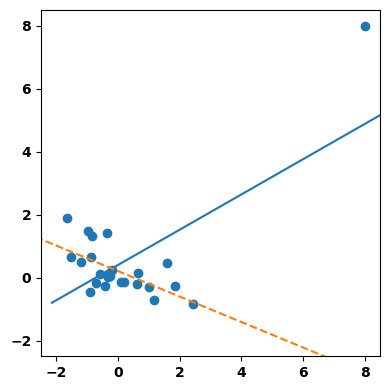

In [41]:
%matplotlib inline
from scipy.stats import linregress

np.random.seed(5)
x = np.random.normal(size=25)
y = -x / 5 + np.random.normal(size=25)
x[0] = 8
y[0] = 8

def abline(slope, intercept, ax):
    """Calculate coordinates of a line based on slope and intercept"""
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(x, y)
slope, intercept, _, _, _ = linregress(x, y)
ax.plot(*abline(slope, intercept, ax))
slope, intercept, _, _, _ = linregress(x[1:], y[1:])
ax.plot(*abline(slope, intercept, ax), '--')
ax.set_xlim(-2.5, 8.5)
ax.set_ylim(-2.5, 8.5)

plt.tight_layout()
plt.show()

# Interpretarea ecuației de regresie

În știința datelor, cea mai importantă utilizare a regresiei este de a prezice o anumită variabilă dependentă
(covariată). În unele cazuri, totuși, obținerea de informații din ecuație
însuși pentru a înțelege natura relației dintre predictori și
rezultatul observat poate fi de valoare. Această secțiune oferă îndrumări pentru examinarea
ecuația de regresie și interpretarea acesteia.

## Predictori corelați

TERMENI CHEIE PENTRU INTERPRETAREA ECUAȚIEI DE REGRESIE
### Variabile corelate
> Atunci când variabilele predictoare sunt foarte corelate, este dificil de interpretat efectul
coeficienților.
### Multicoliniaritate
> Când variabilele predictoare au o corelație perfectă sau aproape perfectă, regresia poate fi
instabil sau imposibil de calculat.
### Variabile confundate
> Un predictor important care, atunci când este omis, duce la relații false într-o ecuație de regresie.

#### Cum a distrus o variabilă confundată experimentul referitor la muzică şi la rezolvarea de puzzle-uri al unui student?
<a href=https://www.scientia.ro/homo-humanus/107-introducere-in-psihologie-de-russ-dewey/4540-variabilele-confundate.html>(sursa)</a>

Un student la psihologie nu a apreciat variabilele confundate la adevărata lor valoare până nu a realizat o cercetare pentru un curs de psihologie experimentală. Ipoteza lui era aceea că genul de muzică ce se aude în fundal afectează performanţele obţinute în cazul sarcinilor complexe. Subiecţii au încercat să rezolve anagrame (puzzle-uri de cuvinte) în timp ce pe fundal se auzea muzică. Grupul nr. 1 a ascultat acordurile liniştitoare ale unui cântec vechi de-al fraţilor Allman, ”Dedicat Elizabethei Reed”. Grupul nr. 2 a ascultat un cântec incredibil de strident şi de repetitiv: ”Brainwash” al trupei punk Flipper. Însă studentul la psihologie a înregistrat cântecul fraţilor Allman la un volum mai mare şi a observat în timpul experimentului că subiecţii se descurcau mai prost ascultându-l pe acesta. Aşa cum a afirmat el:

”Am realizat dintr-o dată că experimentul meu era distrus. Nu puteam să-mi dau seama dacă se descurcau mai prost din cauza diferenţei dintre genurile de muzică sau a diferenţei de volum. Apoi am înţeles cu adevărat conceptul de variabile confundate pentru prima dată.” 

În cazul unei comparaţii între grupuri, o variabilă confundată este orice diferenţă dintre grupuri, alta decât aceea pe care experimentatorul o creează în mod deliberat. O variabilă confundată distruge orice încercare de a identifica o relaţie de tipul cauză-efect, deoarece furnizează o explicaţie alternativă pentru rezultate. Dacă un ”efect” este observat, nimeni nu poate spune că se datorează manipulării variabilei independente sau prezenţei variabilei confundate. Aşadar, variabilele confundabile (sau ”confundate”) trebuie eliminate de fiecare dată când acest lucru este posibil.

### Efecte principale
> Relația dintre un predictor și variabila rezultat, independent de alte variabile.
### Interacțiuni
> O relație de interdependență între doi sau mai mulți predictori și răspuns.

## APENDIX

# A1. Modelarea regresiei cu modulul `statsmodels`

Acest pachet are două moduri diferite de a specifica modelul, una care este similară cu scikit-learn și una care permite specificarea formulelor în stil R.

Aici folosim prima abordare. Deoarece statsmodels nu adaugă automat intercept-ul, trebuie să adăugăm o coloană constantă cu valoarea 1 la predictori. Putem folosi metoda panda de atribuire pentru aceasta.

Statistica t - și imaginea sa în oglindă, valoarea p - măsoară când un coeficient este „semnificativ statistic” — adică în afara intervalului de valori ce s-ar putea produce printr-un aranjament întâmplător al predictorului și al variabilei țintă.

`info` Cu cât statistica t este mai mare (și cu cât valoarea p este mai mică), cu atât este mai semnificativ
predictorul. Deoarece parcimonia este o caracteristică valoroasă a modelului, este util să aveți un instrument
ca aceasta pentru a ghida alegerea variabilelor de inclus ca predictori.

In [42]:
# observați al doilea parametru unde se specifică o coloană constantă 1 pentru termenii liber, "intercept"
model = sm.OLS(house[outcome], house[predictors].assign(const=1))

# antrenarea se face așa cum am mai văzut cu metoda "fit" - a potrivi
results = model.fit()

# deoarece este un modul dedicat statisticii, raportarea rezultatelor de antrenament este mai elaborată
# asta și pentru că regresia este unul din cele mai vechi modele de învățare automată supravegheată
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.541
Model:                            OLS   Adj. R-squared:                  0.540
Method:                 Least Squares   F-statistic:                     5338.
Date:                Tue, 18 Nov 2025   Prob (F-statistic):               0.00
Time:                        22:21:20   Log-Likelihood:            -3.1517e+05
No. Observations:               22687   AIC:                         6.304e+05
Df Residuals:                   22681   BIC:                         6.304e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
SqFtTotLiving   228.8306      3.899     58.694

## Selectarea covariatelor și regresia pas-cu-pas

In [43]:
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms',
              'BldgGrade', 'PropertyType', 'NbrLivingUnits',
              'SqFtFinBasement', 'YrBuilt', 'YrRenovated', 
              'NewConstruction']

X = pd.get_dummies(house[predictors], drop_first=True, dtype=int)
X['NewConstruction'] = [1 if nc else 0 for nc in X['NewConstruction']]

house_full = sm.OLS(house[outcome], X.assign(const=1))
results = house_full.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.595
Model:                            OLS   Adj. R-squared:                  0.594
Method:                 Least Squares   F-statistic:                     2771.
Date:                Tue, 18 Nov 2025   Prob (F-statistic):               0.00
Time:                        22:21:20   Log-Likelihood:            -3.1375e+05
No. Observations:               22687   AIC:                         6.275e+05
Df Residuals:                   22674   BIC:                         6.276e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
SqFtTotLiving       

Pentru a exemplifica selecția pas-cu-pas putem folosi metoda `stepwise_selection` din modulul _dmba_ package.

In [44]:
y = house[outcome]

def train_model(variables):
    if len(variables) == 0:
        return None
    model = LinearRegression()
    model.fit(X[variables], y)
    return model

def score_model(model, variables):
    if len(variables) == 0:
        return AIC_score(y, [y.mean()] * len(y), model, df=1)
    return AIC_score(y, model.predict(X[variables]), model)

best_model, best_variables = stepwise_selection(X.columns, train_model, score_model, 
                                                verbose=True)

print()
print(f'Intercept: {best_model.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(best_variables, best_model.coef_):
    print(f' {name}: {coef}')

Variables: SqFtTotLiving, SqFtLot, Bathrooms, Bedrooms, BldgGrade, NbrLivingUnits, SqFtFinBasement, YrBuilt, YrRenovated, NewConstruction, PropertyType_Single Family, PropertyType_Townhouse
Start: score=647988.32, constant
Step: score=633013.35, add SqFtTotLiving
Step: score=630793.74, add BldgGrade
Step: score=628230.29, add YrBuilt
Step: score=627784.16, add Bedrooms
Step: score=627602.21, add Bathrooms
Step: score=627525.65, add PropertyType_Townhouse
Step: score=627525.08, add SqFtFinBasement
Step: score=627524.98, add PropertyType_Single Family
Step: score=627524.98, unchanged None

Intercept: 6178645.017
Coefficients:
 SqFtTotLiving: 199.2775530420158
 BldgGrade: 137159.5602261976
 YrBuilt: -3565.424939249463
 Bedrooms: -51947.38367361413
 Bathrooms: 42396.16452772056
 PropertyType_Townhouse: 84479.16203299937
 SqFtFinBasement: 7.046974967583083
 PropertyType_Single Family: 22912.05518701767


## Puntea curs → seminar

**Concepte cheie**

1. **Modelul liniar** și interpretarea coeficienților.
2. **Măsuri de eroare:** R², MAE, RMSE, MAPE; ce spune fiecare.
3. **Supraînvățare** și compromisul **bias-variance**: train bun, test slab.
4. **Regularizare:** Ridge și Lasso penalizează coeficienții mari; Lasso poate elimina predictori.

**Ce ceri asistentului AI** (exemplu de cerere)

> Pe tabelul `train` din `lab-set6`, prezice `SalePrice` cu regresie liniară folosind 5 predictori numerici aleși după corelația cu ținta. Pune deoparte 20% date de test, raportează RMSE și R² pe antrenare și pe test, apoi compară cu Ridge și Lasso cu `alpha` ales prin validare încrucișată.

**Ce verifici înainte să accepți rezultatul**

- [ ] setul de test a fost separat înainte de alegerea predictorilor și a lui `alpha`;
- [ ] compari eroarea pe antrenare cu cea pe test (supraînvățare?);
- [ ] semnul și mărimea coeficienților au sens pentru problemă.

Continuăm la seminar: [seminar-04-regresie.ipynb](seminar-04-regresie.ipynb).